In [32]:
import numpy as np
import jax
import jax.numpy as jnp
import pypesto
from pypesto.result import OptimizerResult
import pypesto.profile as profile
from cmfa.functions import ordered_ilr_func, calculate_ci

import sys
sys.path.insert(0, "../scripts")
import toy_network
import tca_cycle

import pickle
from pathlib import Path

from functools import partial

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba

from jax import config

config.update("jax_enable_x64", True)

import scipy.stats as stats
import optimistix

SEED = 1234
key = jax.random.key(seed=SEED)
key_toy, key = jax.random.split(key)
key_tca, key = jax.random.split(key)
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

combined = "#8CAA8D"

IDX_TOY = 4699
IDX_TCA = 5741

def fisher_interval(log_flux_est, flux_sd):
    mu = log_flux_est
    sigma = flux_sd
    x_start = (mu - 2.4 * sigma)
    x_end = (mu + 2.4 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)
    
    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)
    y_scaled = y_raw / np.max(y_raw)

    return np.exp(x_axis), y_scaled

In [33]:
# Toy network
true_mid_toy = np.load(RESULTS_DIR_TOY / "true_composition.npy")
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
simulated_mid_toy = jnp.load(RESULTS_DIR_TOY / "id_simulated_reference.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

random_sim_toy = simulated_mid_toy[IDX_TOY]

sd_trad_toy = np.std(simulated_mid_toy, axis=0)
sd_ilr_toy = np.std(ordered_ilr_func(simulated_mid_toy), axis=0)

weights_trad_toy = 1/sd_trad_toy
weights_ilr_toy = 1/sd_ilr_toy

# 2. Optimization with Optimistix
# Note: Ensure loss_trad signature is: loss_trad(params, args)
init_guess_toy = jnp.array([100.0, 50.0])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_toy = optimistix.minimise(
    toy_network.loss_trad,
    y0=jnp.log(init_guess_toy),
    args=(random_sim_toy, weights_trad_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_toy = optimistix.minimise(
    toy_network.loss_ilr,
    y0=jnp.log(init_guess_toy),
    args=(random_sim_toy, weights_ilr_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

est_trad_toy = estimated_fluxes_toy["trad"][:, [4, 5]]
est_ilr_toy = estimated_fluxes_toy["ilr"][:, [4, 5]]

inv_hessian_trad_toy = opt_result_trad_toy.state.f_info.hessian_inv.pytree
standard_errors_trad_toy = jnp.sqrt(jnp.diag(inv_hessian_trad_toy))

inv_hessian_ilr_toy = opt_result_ilr_toy.state.f_info.hessian_inv.pytree
standard_errors_ilr_toy = jnp.sqrt(jnp.diag(inv_hessian_ilr_toy))


In [34]:
# tca cycle
true_mid_tca = np.load(RESULTS_DIR_TCA / "true_composition.npy", allow_pickle=True).item()
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True)
simulated_mid_tca = jnp.load(RESULTS_DIR_TCA / "id_simulated_reference.pkl", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

random_sim_tca = jax.tree.map(lambda x: x[IDX_TCA], simulated_mid_tca)

sd_trad_tca = jax.tree.map(lambda x: np.std(x, axis=0), simulated_mid_tca)
sd_ilr_tca = jax.tree.map(lambda x: np.std(ordered_ilr_func(x), axis=0), simulated_mid_tca)

weights_trad_tca = jax.tree.map(lambda s: 1/s, sd_trad_tca)
weights_ilr_tca = jax.tree.map(lambda s: 1/s, sd_ilr_tca)

init_guess_tca = np.array([0.2, 0.2, 0.2])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_tca = optimistix.minimise(
    tca_cycle.loss_trad,
    y0=jnp.log(init_guess_tca),
    args=(random_sim_tca, weights_trad_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_tca = optimistix.minimise(
    tca_cycle.loss_ilr,
    y0=jnp.log(init_guess_tca),
    args=(random_sim_tca, weights_ilr_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

est_trad_tca = estimated_fluxes_tca["trad"]
est_ilr_tca = estimated_fluxes_tca["ilr"]

inv_hessian_trad_tca = opt_result_trad_tca.state.f_info.hessian_inv.pytree
standard_errors_trad_tca = jnp.sqrt(jnp.diag(inv_hessian_trad_tca))

inv_hessian_ilr_tca = opt_result_ilr_tca.state.f_info.hessian_inv.pytree
standard_errors_ilr_tca = jnp.sqrt(jnp.diag(inv_hessian_ilr_tca))

C:\Users\afjsl\AppData\Local\Temp\ipykernel_14960\1402540059.py:71: RuntimeWarning: overflow encountered in exp
  return np.exp(x_axis), y_scaled


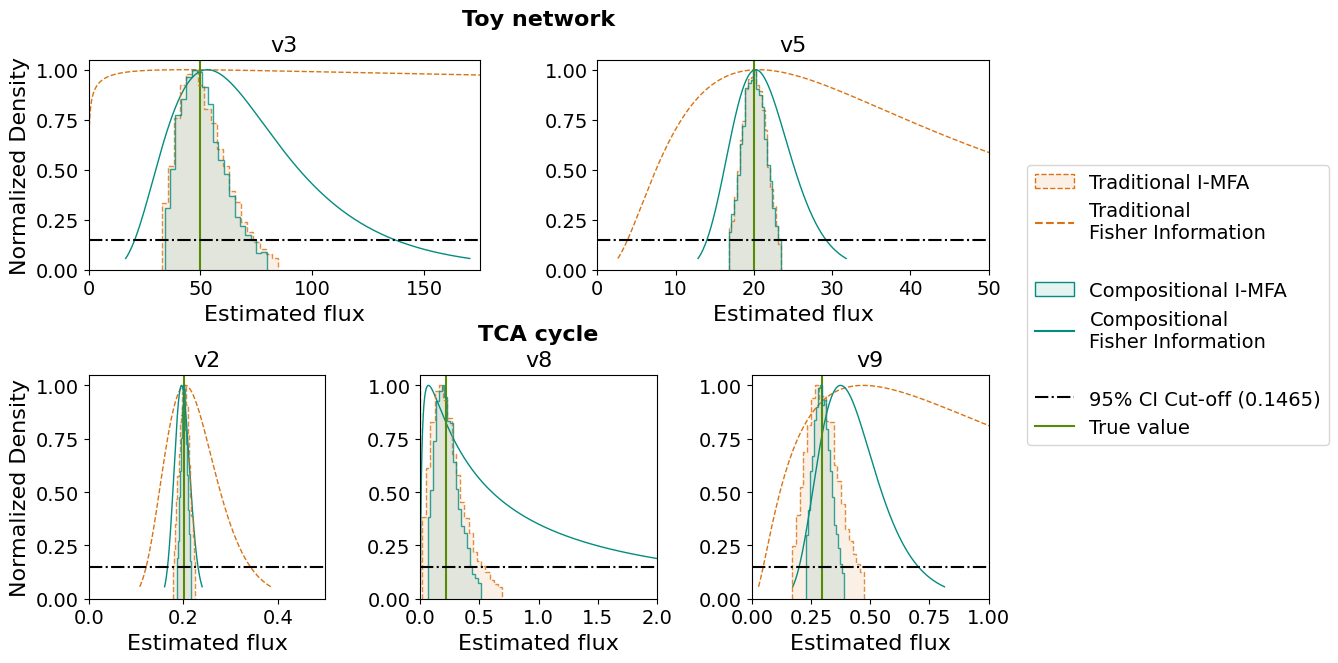

In [35]:
# --- Figure & Layout Setup ---
f = plt.figure(figsize=(10, 7))
 
# Top Row (Toy Network) — top lowered from 0.88 → 0.76 to leave room for the legend
gs1 = gridspec.GridSpec(1, 2, left=0.05, right=0.95, top=0.85, bottom=0.55, wspace=0.3)
ax1, ax2 = plt.subplot(gs1[0]), plt.subplot(gs1[1])
f.add_subplot(gs1[:, :], frameon=False).set_title("Toy network", fontsize=16, fontweight='bold', pad=25)
plt.axis('off')
 
# Bottom Row (TCA Cycle)
gs2 = gridspec.GridSpec(1, 3, left=0.05, right=0.95, top=0.40, bottom=0.08, wspace=0.4)
ax3, ax4, ax5 = plt.subplot(gs2[0]), plt.subplot(gs2[1]), plt.subplot(gs2[2])
f.add_subplot(gs2[:, :], frameon=False).set_title("TCA cycle", fontsize=16, fontweight='bold', pad=25)
plt.axis('off')
 
axes = [ax1, ax2, ax3, ax4, ax5]
 
# --- Unified Subplot Configuration ---
configs = [
    # Toy Network Subplots
    {"idx": 0, "true_value": true_flux_toy[2], "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0], "title": "v3", "xlim": (0, 175)},
    {"idx": 1, "true_value": true_flux_toy[4], "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 1], "est_i": est_ilr_toy[:, 1], "title": "v5", "xlim": (0, 50)},
    # TCA Cycle Subplots
    {"idx": 1, "true_value": true_flux_tca.item()["v2"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 1], "est_i": est_ilr_tca[:, 1], "title": "v2", "xlim": (0, 0.5)},
    {"idx": 0, "true_value": true_flux_tca.item()["v8"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 0], "est_i": est_ilr_tca[:, 0], "title": "v8", "xlim": (0, 2)},
    {"idx": 2, "true_value": true_flux_tca.item()["v9"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 2], "est_i": est_ilr_tca[:, 2], "title": "v9", "xlim": (0, 1)},
]
 
# --- Execution Loop ---
for ax, cfg in zip(axes, configs):
    idx = cfg["idx"]
    et, ei = cfg["est_t"].flatten(), cfg["est_i"].flatten()

    # 2. Fisher Information Intervals
    ax.plot(*fisher_interval(cfg["opt_t"].value[idx], cfg["se_t"][idx]), color=TRAD, lw=1, linestyle = "--")
    ax.plot(*fisher_interval(cfg["opt_i"].value[idx], cfg["se_i"][idx]), color=ILR, lw=1)
    ax.axvline(cfg["true_value"], color= OLIVE)
    # 3. Peak-Normalized Histograms
    bins_et = np.linspace(np.quantile(et, 0.025), np.quantile(et, 0.975), 20)
    bins_ei = np.linspace(np.quantile(ei, 0.025), np.quantile(ei, 0.975), 20)
    ax.hist(et, bins=bins_et, weights=np.ones_like(et) / np.max(np.histogram(et, bins=bins_et)[0]), histtype='step', color=TRAD, alpha=0.8, linestyle="--")
    ax.hist(ei, bins=bins_ei, weights=np.ones_like(ei) / np.max(np.histogram(ei, bins=bins_ei)[0]), histtype='step', color=ILR, alpha=0.8, linestyle="-")
    ax.hist(et, bins=bins_et, weights=np.ones_like(et) / np.max(np.histogram(et, bins=bins_et)[0]), color=TRAD, alpha=0.1)
    ax.hist(ei, bins=bins_ei, weights=np.ones_like(ei) / np.max(np.histogram(ei, bins=bins_ei)[0]), color=ILR, alpha=0.1)
 
    # 4. Global Subplot Formatting
    ax.axhline(0.1465, color="black", linestyle="-.")
    ax.set_title(cfg["title"], fontsize=16)
    ax.set_xlim(cfg["xlim"])
    ax.set_xlabel("Estimated flux", fontsize=16)
    ax.tick_params(axis='both', labelsize=14)
    # Y-axis label only on leftmost subplot per row (ax1 for Toy Network, ax3 for TCA Cycle)
    if ax in [ax1, ax3]:
        ax.set_ylabel("Normalized Density", fontsize=16)
 
# --- Legend & Figure Output ---
# 1. Define the elements individually for easy sorting
trad_mfa = mpatches.Patch(edgecolor=TRAD, linestyle="--", facecolor=to_rgba(TRAD, alpha=0.1))
trad_fish = Line2D([0], [0], color=TRAD, linestyle="--", markersize=6)
 
comp_mfa  = mpatches.Patch(edgecolor=ILR, linestyle="-", facecolor=to_rgba(ILR, alpha=0.1))
comp_fish = Line2D([0], [0], color=ILR, linestyle="-", markersize=6)

true_val = Line2D([0], [0], color=OLIVE, linestyle="-", markersize=6)

cutoff    = Line2D([0], [0], color="black", linestyle="-.", markersize=6)
dummy     = Line2D([], [], linestyle="")  # Invisible spacer to hold the grid shape

 
# 2. Arrange them explicitly row-by-row so they line up column-by-column
# Row 1: MFAST / MFAC / Cutoff
# Row 2: Profile T / Profile C / Blank Spacer
# Row 3: Fisher T / Fisher C
custom_markers = [
    trad_mfa, trad_fish, dummy,
    comp_mfa, comp_fish, dummy,
    cutoff, true_val
]

custom_labels = [
    "Traditional I-MFA", "Traditional\nFisher Information", "",             
    "Compositional I-MFA", "Compositional\nFisher Information", "",
     "95% CI Cut-off (0.1465)", "True value",    
]

# 3. Render the centered 3-column legend
f.legend(
    custom_markers,
    custom_labels,
    fontsize=14,
    loc="right",
    bbox_to_anchor=(1.3, 0.5),
    ncol=1,
)
 
plt.savefig(PLOT_DIR / 'CI.svg', dpi=600, bbox_inches='tight', pad_inches=0.12)
plt.show()
 


In [36]:
# est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0]
mc_toy_trad = np.array([[np.quantile(est_trad_toy[:, 0], 0.025), np.quantile(est_trad_toy[:, 0], 0.975)], 
                        [np.quantile(est_trad_toy[:, 1], 0.025), np.quantile(est_trad_toy[:, 1], 0.975)]])

mc_toy_ilr = np.array([[np.quantile(est_ilr_toy[:, 0], 0.025), np.quantile(est_ilr_toy[:, 0], 0.975)], 
                        [np.quantile(est_ilr_toy[:, 1], 0.025), np.quantile(est_ilr_toy[:, 1], 0.975)]])

mc_tca_trad = np.array([[np.quantile(est_trad_tca[:, 0], 0.025), np.quantile(est_trad_tca[:, 0], 0.975)], 
                        [np.quantile(est_trad_tca[:, 1], 0.025), np.quantile(est_trad_tca[:, 1], 0.975)],
                        [np.quantile(est_trad_tca[:, 2], 0.025), np.quantile(est_trad_tca[:, 2], 0.975)]])

mc_tca_ilr = np.array([[np.quantile(est_ilr_tca[:, 0], 0.025), np.quantile(est_ilr_tca[:, 0], 0.975)], 
                        [np.quantile(est_ilr_tca[:, 1], 0.025), np.quantile(est_ilr_tca[:, 1], 0.975)],
                        [np.quantile(est_ilr_tca[:, 2], 0.025), np.quantile(est_ilr_tca[:, 2], 0.975)]])

In [37]:
print(mc_toy_trad)
print(mc_toy_ilr)

[[32.61936979 84.62397076]
 [16.77060508 23.48504079]]
[[33.98657867 79.70724945]
 [16.77721228 23.42448322]]


In [38]:
print(mc_tca_trad)
print(mc_tca_ilr)

[[0.01490581 0.69355434]
 [0.17754027 0.22430539]
 [0.16961864 0.4737642 ]]
[[0.06284598 0.51100041]
 [0.18705802 0.21619725]
 [0.22832877 0.39005526]]


In [39]:
np.median(est_trad_tca[:, 2])

np.float64(0.2957913867361436)

In [40]:
np.median(est_ilr_tca[:, 2])

np.float64(0.295839870919572)

In [41]:
def get_sigma_v(N, inv_hessian, ix_input_flux):
    n_nofixed = jnp.delete(N, ix_input_flux, axis=1)
    # jax.debug.breakpoint()
    return n_nofixed @ inv_hessian @ n_nofixed.T

In [42]:
m_toy = jnp.array([[-1, -1, 2], [0, 0, -1], [-1, 0, 1]])
n_toy = jnp.vstack([-m_toy, jnp.eye(3)])
ix_input_flux_toy = np.array([0])

sigma_v_trad = get_sigma_v(n_toy, inv_hessian_trad_toy, ix_input_flux_toy)
v3_trad, v5_trad = jnp.exp(opt_result_trad_toy.value)

v_free_trad = jnp.array([100, v3_trad, v5_trad])
# The fluxes calcualted from M and the free fluxes
v_full_trad = n_toy @ v_free_trad

flux_ci_toy_trad = calculate_ci(sigma_v_trad, jnp.log(v_full_trad))
print(flux_ci_toy_trad)

[[1.43406914e-02 7.25306208e+05]
 [3.82530770e+00 1.10873796e+02]
 [1.47492606e+01 4.27496724e+02]
 [1.00000000e+02 1.00000000e+02]
 [3.14819460e-04 5.92135000e+06]
 [3.82530770e+00 1.10873796e+02]]


In [43]:
sigma_v_ilr = get_sigma_v(n_toy, inv_hessian_ilr_toy, ix_input_flux_toy)
v3_ilr, v5_ilr = jnp.exp(opt_result_ilr_toy.value)

v_free_ilr = jnp.array([100, v3_ilr, v5_ilr])
# The fluxes calcualted from M and the free fluxes
v_full_ilr = n_toy @ v_free_ilr

flux_ci_toy_ilr = calculate_ci(sigma_v_ilr, jnp.log(v_full_ilr))
print(flux_ci_toy_ilr)

[[ 21.34838035 594.6908955 ]
 [ 13.97798304  29.2632703 ]
 [ 55.13518887 115.42694899]
 [100.         100.        ]
 [ 20.50287923 137.6505528 ]
 [ 13.97798304  29.2632703 ]]


In [44]:
V_FREE = {"v8": 0.215, "v1": 1, "v19": 0.05, "v20": 0.03, "v16": 0.07, "v17": 0.23, "v18": 0.12, "v2": 0.201, "v9": 0.296}
KNOWN_KEYS = ["v1", "v16", "v17", "v18", "v19", "v20"]
KNOWN_FLUXES = {k: V_FREE[k] for k in KNOWN_KEYS}
FREE_KEYS = ["v8", "v2", "v9"]

flux_from_free = partial(
    tca_cycle.flux_vector,
    fixed=KNOWN_FLUXES,
)
n_tca = tca_cycle.get_N()
ix_input_flux_tca = np.array([1,2,3,4,5,6])

In [45]:
flux_est_trad = flux_from_free(jnp.exp(opt_result_trad_tca.value))
sigma_v_tca_trad = get_sigma_v(n_tca, inv_hessian_trad_tca, ix_input_flux_tca)
flux_est_jax = jnp.array([flux_est_trad[k] for k in flux_est_trad.keys()])
flux_ci_tca_trad = calculate_ci(sigma_v_tca_trad, jnp.log(flux_est_jax))
print(flux_ci_tca_trad)

[[0.00000000e+00            inf]
 [1.00000000e+00 1.00000000e+00]
 [5.00000000e-02 5.00000000e-02]
 [3.00000000e-02 3.00000000e-02]
 [7.00000000e-02 7.00000000e-02]
 [2.30000000e-01 2.30000000e-01]
 [1.20000000e-01 1.20000000e-01]
 [1.21084967e-01 3.42341994e-01]
 [4.76228511e-02 4.64529154e+00]
 [3.70868795e-01 1.04855265e+00]
 [3.70868795e-01 1.04855265e+00]
 [3.70868795e-01 1.04855265e+00]
 [2.11226352e-01 1.68844918e+00]
 [2.56796034e-01 5.80360913e+00]
 [1.77583690e-01 5.02080117e-01]
 [1.90077560e-01 1.21453669e+01]
 [1.30051409e-01 2.34944238e+01]
 [2.73144278e-03 1.07979531e+04]
 [8.73364695e-02 4.78926350e+00]
 [0.00000000e+00            inf]]


In [46]:
flux_est_ilr = flux_from_free(jnp.exp(opt_result_ilr_tca.value))
sigma_v_tca_ilr = get_sigma_v(n_tca, inv_hessian_ilr_tca, ix_input_flux_tca)
flux_est_jax_ilr = jnp.array([flux_est_ilr[k] for k in flux_est_ilr.keys()])
flux_ci_tca_ilr = calculate_ci(sigma_v_tca_ilr, jnp.log(flux_est_jax_ilr))
print(flux_ci_tca_ilr)

[[1.88895258e-03 2.55399661e+00]
 [1.00000000e+00 1.00000000e+00]
 [5.00000000e-02 5.00000000e-02]
 [3.00000000e-02 3.00000000e-02]
 [7.00000000e-02 7.00000000e-02]
 [2.30000000e-01 2.30000000e-01]
 [1.20000000e-01 1.20000000e-01]
 [1.66404252e-01 2.31048645e-01]
 [1.99057678e-01 7.05565595e-01]
 [5.22838796e-01 7.25950172e-01]
 [5.22838796e-01 7.25950172e-01]
 [5.22838796e-01 7.25950172e-01]
 [4.19279642e-01 8.08317142e-01]
 [7.32378540e-01 1.96043582e+00]
 [2.47026351e-01 3.42990657e-01]
 [7.72521078e-01 2.87121929e+00]
 [7.52922941e-01 3.88548791e+00]
 [3.72874776e-01 7.81626692e+01]
 [3.05073474e-01 1.02312331e+00]
 [1.54664274e-02 2.74534261e+01]]


In [47]:
# reduction
for i in np.array([4, 5]):
    print(((flux_ci_toy_trad[i,1]-flux_ci_toy_trad[i,0]) - (flux_ci_toy_ilr[i,1]-flux_ci_toy_ilr[i,0]))/(flux_ci_toy_trad[i,1]-flux_ci_toy_trad[i,0]))

for i in np.array([0, 7, 8]):
    print(((flux_ci_tca_trad[i,1]-flux_ci_tca_trad[i,0]) - (flux_ci_tca_ilr[i,1]-flux_ci_tca_ilr[i,0]))/(flux_ci_tca_trad[i,1]-flux_ci_tca_trad[i,0]))

0.9999802160531782
0.8572115538272118
nan
0.7078312319639115
0.8898337502160639


In [48]:
np.mean(np.array([0.9999789570160221,
                0.856660455317294,
                0.9761211861278558,
                0.7863170530498749,
                0.9368913794559693]))

np.float64(0.9111938061934032)

## Profile likelihood

In [49]:
with open(RESULTS_DIR_TOY / "profile_likelihood.pkl", "rb") as f:
    profile_toy = pickle.load(f)
with open(RESULTS_DIR_TCA / "profile_likelihood.pkl", "rb") as f:
    profile_tca = pickle.load(f)

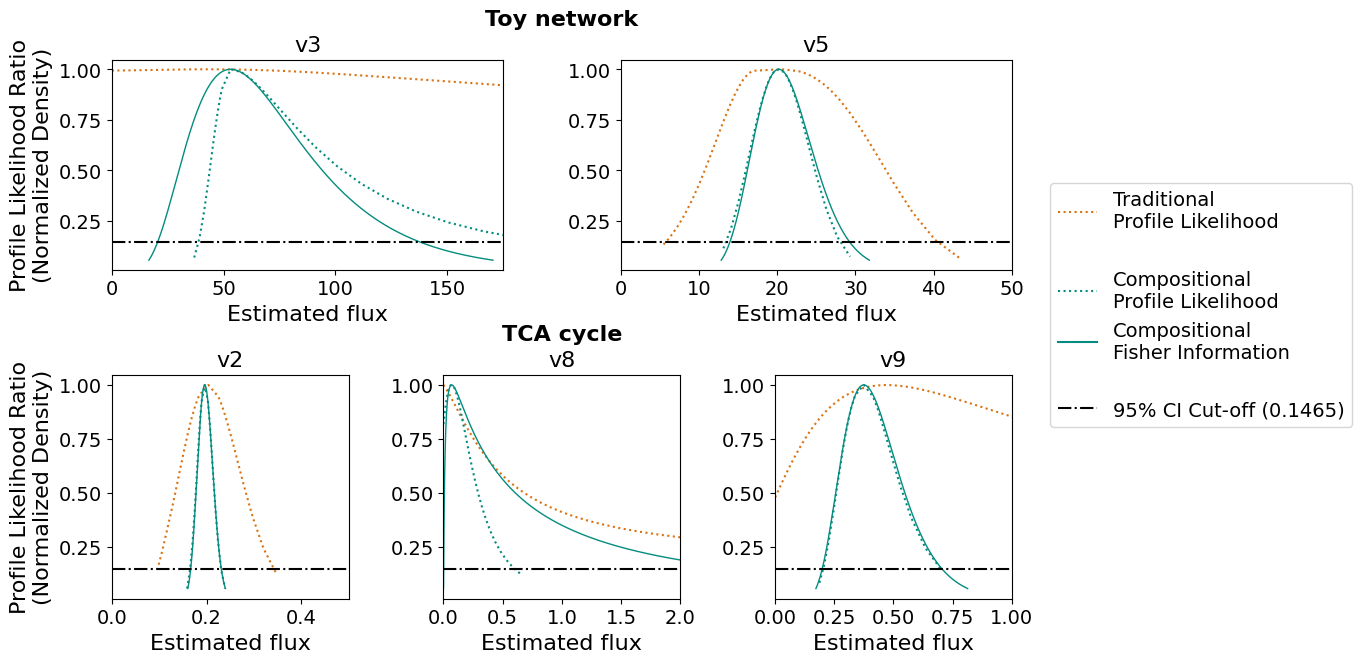

In [50]:
# --- Figure & Layout Setup ---
f = plt.figure(figsize=(10, 7))
 
# Top Row (Toy Network) — top lowered from 0.88 → 0.76 to leave room for the legend
gs1 = gridspec.GridSpec(1, 2, left=0.05, right=0.95, top=0.85, bottom=0.55, wspace=0.3)
ax1, ax2 = plt.subplot(gs1[0]), plt.subplot(gs1[1])
f.add_subplot(gs1[:, :], frameon=False).set_title("Toy network", fontsize=16, fontweight='bold', pad=25)
plt.axis('off')
 
# Bottom Row (TCA Cycle)
gs2 = gridspec.GridSpec(1, 3, left=0.05, right=0.95, top=0.40, bottom=0.08, wspace=0.4)
ax3, ax4, ax5 = plt.subplot(gs2[0]), plt.subplot(gs2[1]), plt.subplot(gs2[2])
f.add_subplot(gs2[:, :], frameon=False).set_title("TCA cycle", fontsize=16, fontweight='bold', pad=25)
plt.axis('off')
 
axes = [ax1, ax2, ax3, ax4, ax5]

configs = [
    # Toy Network Subplots
    {"res_t": profile_toy["trad"]["v3"], "res_i": profile_toy["ilr"]["v3"], "idx": 0, "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0], "title": "v3", "xlim": (0, 175)},
    {"res_t": profile_toy["trad"]["v5"], "res_i": profile_toy["ilr"]["v5"], "idx": 1, "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 1], "est_i": est_ilr_toy[:, 1], "title": "v5", "xlim": (0, 50)},
    # TCA Cycle Subplots
    {"res_t": profile_tca["trad"]["v2"], "res_i": profile_tca["ilr"]["v2"], "idx": 1, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 1], "est_i": est_ilr_tca[:, 1], "title": "v2", "xlim": (0, 0.5)},
    {"res_t": profile_tca["trad"]["v8"], "res_i": profile_tca["ilr"]["v8"], "idx": 0, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 0], "est_i": est_ilr_tca[:, 0], "title": "v8", "xlim": (0, 2)},
    {"res_t": profile_tca["trad"]["v9"], "res_i": profile_tca["ilr"]["v9"], "idx": 2, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 2], "est_i": est_ilr_tca[:, 2], "title": "v9", "xlim": (0, 1)},
]

 
# --- Execution Loop ---
for ax, cfg in zip(axes, configs):
    idx, rt, ri = cfg["idx"], cfg["res_t"], cfg["res_i"]
    et, ei = cfg["est_t"].flatten(), cfg["est_i"].flatten()
 
    # 1. Profile Likelihood Paths
    ax.plot(rt[0,:], rt[1,:], color=TRAD, linestyle=":")
    ax.plot(ri[0,:], ri[1,:], color=ILR, linestyle=":")
 
    # 2. Fisher Information Intervals
    # ax.plot(*fisher_interval(cfg["opt_t"].value[idx], cfg["se_t"][idx]), color=TRAD, lw=1)
    ax.plot(*fisher_interval(cfg["opt_i"].value[idx], cfg["se_i"][idx]), color=ILR, lw=1)

    # 4. Global Subplot Formatting
    ax.axhline(0.1465, color="black", linestyle="-.")
    ax.set_title(cfg["title"], fontsize=16)
    ax.set_xlim(cfg["xlim"])
    ax.set_xlabel("Estimated flux", fontsize=16)
    ax.tick_params(axis='both', labelsize=14)
    # Y-axis label only on leftmost subplot per row (ax1 for Toy Network, ax3 for TCA Cycle)
    if ax in [ax1, ax3]:
        ax.set_ylabel("Profile Likelihood Ratio\n(Normalized Density)", fontsize=16)
 
# --- Legend & Figure Output ---
# 1. Define the elements individually for easy sorting
trad_prof = Line2D([0], [0], color=TRAD, linestyle=":", markersize=6)
trad_fish = Line2D([0], [0], color=TRAD, linestyle="-", markersize=6)

comp_prof = Line2D([0], [0], color=ILR, linestyle=":", markersize=6)
comp_fish = Line2D([0], [0], color=ILR, linestyle="-", markersize=6)
 
cutoff    = Line2D([0], [0], color="black", linestyle="-.", markersize=6)
dummy     = Line2D([], [], linestyle="")  # Invisible spacer to hold the grid shape
 
# 2. Arrange them explicitly row-by-row so they line up column-by-column
# Row 1: MFAST / MFAC / Cutoff
# Row 2: Profile T / Profile C / Blank Spacer
# Row 3: Fisher T / Fisher C
custom_markers = [
    trad_prof, dummy,
    comp_prof, comp_fish, dummy,
    cutoff,
]

custom_labels = [
    "Traditional\nProfile Likelihood", "",             
    "Compositional\nProfile Likelihood", "Compositional\nFisher Information", "",
     "95% CI Cut-off (0.1465)",    
]
 
# 3. Render the centered 3-column legend
f.legend(
    custom_markers,
    custom_labels,
    fontsize=14,
    loc="right",
    bbox_to_anchor=(1.3, 0.5),
    ncol=1,
)
 
# Render main title slightly higher to clear the 3-row legend blocks
plt.savefig(PLOT_DIR / 'profile_likelihood.svg', dpi=600, bbox_inches='tight', pad_inches=0.12)
plt.show()

In [51]:
profile_cis_toy_trad = profile_toy["trad"]["ci"]
profile_cis_toy_ilr = profile_toy["ilr"]["ci"]
print(profile_cis_toy_trad)
print(profile_cis_toy_ilr)

[[9.11881966e-04 1.09663316e+03]
 [5.78262052e+00 4.05456283e+01]]
[[ 38.71032381 194.52247796]
 [ 13.45763498  28.11617879]]


In [52]:
profile_cis_tca_trad = profile_tca["trad"]["ci"]
profile_cis_tca_ilr = profile_tca["ilr"]["ci"]
print(profile_cis_tca_trad)
print(profile_cis_tca_ilr)

[[7.43390869e-16 1.09663316e+03]
 [9.65162538e-02 3.42209752e-01]
 [9.11881966e-04 1.09663316e+03]]
[[0.00091188 0.60327187]
 [0.1652592  0.23061413]
 [0.20308363 0.70011471]]


In [53]:
LB  = np.exp(-7)   # profile search lower bound (~9.11e-4)
UB  = np.exp(7)   # profile search upper bound for toy (~1.09e3)

def fmt(x):
    if np.isinf(x):
        return "-inf" if x < 0 else "inf"
    mantissa, exp_str = f"{x:.4e}".split("e")
    return rf"\num{{{mantissa}e{int(exp_str)}}}"

def ci_cell(lo, hi, lo_bound=None, hi_bound=None):
    lo_inf, hi_inf = np.isinf(lo), np.isinf(hi)
    lo_star = (not lo_inf) and lo_bound is not None and abs(lo - lo_bound) / lo_bound < 1e-3
    hi_star = (not hi_inf) and hi_bound is not None and abs(hi - hi_bound) / hi_bound < 1e-3
    lo_tex = fmt(lo) if lo_inf else (f"${fmt(lo)}^*$" if lo_star else f"${fmt(lo)}$")
    hi_tex = fmt(hi) if hi_inf else (f"${fmt(hi)}^*$" if hi_star else f"${fmt(hi)}$")
    return "{" + lo_tex + ", " + hi_tex + "}"

def tbl_row(name, mc_t, mc_i, pl_t, pl_i, pl_lb, pl_ub, fi_t, fi_i, vspace="[2pt]"):
    cols = " & ".join([
        ci_cell(mc_t[0], mc_t[1]),
        ci_cell(mc_i[0], mc_i[1]),
        ci_cell(pl_t[0], pl_t[1], pl_lb, pl_ub),
        ci_cell(pl_i[0], pl_i[1], pl_lb, pl_ub),
        ci_cell(fi_t[0], fi_t[1]),
        ci_cell(fi_i[0], fi_i[1]),
    ])
    return f"{name}\n  & {cols} \\\\{vspace}"

rows = [
    # Toy network
    tbl_row("v3",
        mc_toy_trad[0], mc_toy_ilr[0],
        profile_cis_toy_trad[0], profile_cis_toy_ilr[0], LB, UB,
        flux_ci_toy_trad[4], flux_ci_toy_ilr[4]),
    tbl_row("v5",
        mc_toy_trad[1], mc_toy_ilr[1],
        profile_cis_toy_trad[1], profile_cis_toy_ilr[1], LB, UB,
        flux_ci_toy_trad[5], flux_ci_toy_ilr[5], vspace="[4pt]"),
    # TCA cycle — v2 (col 1), v8 (col 0), v9 (col 2) in mc/profile arrays
    #             v8→idx 0, v2→idx 7, v9→idx 8 in flux_ci_tca arrays
    tbl_row("v2",
        mc_tca_trad[1], mc_tca_ilr[1],
        profile_cis_tca_trad[1], profile_cis_tca_ilr[1], LB, UB,
        flux_ci_tca_trad[7], flux_ci_tca_ilr[7]),
    tbl_row("v8",
        mc_tca_trad[0], mc_tca_ilr[0],
        profile_cis_tca_trad[0], profile_cis_tca_ilr[0], LB, UB,
        flux_ci_tca_trad[0], flux_ci_tca_ilr[0]),
    tbl_row("v9",
        mc_tca_trad[2], mc_tca_ilr[2],
        profile_cis_tca_trad[2], profile_cis_tca_ilr[2], LB, UB,
        flux_ci_tca_trad[8], flux_ci_tca_ilr[8], vspace=""),
]

header = r"""\begin{table*}[htbp]
\centering
\setlength{\tabcolsep}{6pt}
\begin{tabular}{l
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]}
\toprule
& \multicolumn{2}{c}{Monte Carlo simulation}
& \multicolumn{2}{c}{Profile likelihood}
& \multicolumn{2}{c}{Fisher information} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
Flux & {Traditional} & {Compositional}
     & {Traditional} & {Compositional}
     & {Traditional} & {Compositional} \\
\midrule
\rowcolor{gray!10}
\multicolumn{7}{l}{\textit{Toy network}} \\[2pt]"""

footer = r"""
\rowcolor{gray!10}
\multicolumn{7}{l}{\textit{TCA cycle}} \\[2pt]"""

caption = r"""
\bottomrule
\end{tabular}
\caption{\textbf{95\% confidence intervals} for all three estimation methods, shown as lower and upper bounds.
An asterisk~($^*$) indicates that the interval reached the outer bounds of the search space.}
\label{tab:cis}
\end{table*}"""

print(header)
print(rows[0])
print(rows[1])
print(footer)
print(rows[2])
print(rows[3])
print(rows[4])
print(caption)

\begin{table*}[htbp]
\centering
\setlength{\tabcolsep}{6pt}
\begin{tabular}{l
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]}
\toprule
& \multicolumn{2}{c}{Monte Carlo simulation}
& \multicolumn{2}{c}{Profile likelihood}
& \multicolumn{2}{c}{Fisher information} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
Flux & {Traditional} & {Compositional}
     & {Traditional} & {Compositional}
     & {Traditional} & {Compositional} \\
\midrule
\rowcolor{gray!10}
\multicolumn{7}{l}{\textit{Toy network}} \\[2pt]
v3
  & {$\num{3.2619e1}$, $\num{8.4624e1}$} & {$\num{3.3987e1}$, $\num{7.9707e1}$} & {$\num{9.1188e-4}^*$, $\num{1.0966e3}^*$} & {$\num{3.8710e1}$, $\num{1.9452e2}$} & {$\num{3.1482e-4}$, $\num{5.9214e6}$} & {$\num{2.0503e1}$, $\num{1.3765e2}$} \\[2pt]
v5
  & {$\num{1.6771e1}$, $\num{2.3485e1}$} & {$\num{1.6777e1}$, $\num{2.3424e1}$} & {$\num{5.7826e0}$, $\num{4.0546e1}$} & {$\num{1.